# Figure 1 — China’s Solar PV Export Capacity by Destination

**Main view:** 2025 annual estimated capacity, Panels + Cells + Wafers, in GW. Darker colors indicate larger recorded exports. **Robustness:** average annual capacity over 2022–2025.



In [ ]:
from pathlib import Path
import io
import pandas as pd

try:
    from google.colab import files
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

if IN_COLAB:
    uploaded = files.upload()
    csv_names = [name for name in uploaded if name.lower().endswith('.csv')]
    if len(csv_names) != 1:
        raise ValueError('Upload exactly one original Ember CSV.')
    source_bytes = uploaded[csv_names[0]]
else:
    candidates = [Path('data/Raw/mart_solar_exports_full_release_monthly.csv'),
                  Path('solar_pv_figure1/data/Raw/mart_solar_exports_full_release_monthly.csv'),
                  Path('mart_solar_exports_full_release_monthly.csv')]
    input_path = next((p for p in candidates if p.exists()), None)
    if input_path is None:
        raise FileNotFoundError('Set input_path to your original Ember CSV.')
    source_bytes = input_path.read_bytes()

df = pd.read_csv(io.BytesIO(source_bytes))
df.head()

,Area,Date,Area type,Region,Commodity code,Commodity type,Amount (items),Amount (kg),Amount (USD),Commodity price,Price unit,Capacity (MW),Cumulative capacity (MW)
0,Afghanistan,2017-01-01,Country or economy,Asia,85414020,Panels,49433,333324.0,1663024.0,0.38,USD/W,4.38,4.38
1,Afghanistan,2017-02-01,Country or economy,Asia,85414020,Panels,5452,82456.0,337723.0,0.38,USD/W,0.89,5.27
2,Afghanistan,2017-03-01,Country or economy,Asia,85414020,Panels,51403,940507.0,3477201.0,0.38,USD/W,9.15,14.42
3,Afghanistan,2017-04-01,Country or economy,Asia,85414020,Panels,100875,1306053.0,4783758.0,0.38,USD/W,12.59,27.00
4,Afghanistan,2017-05-01,Country or economy,Asia,85414020,Panels,67325,786843.0,2823671.0,0.38,USD/W,7.43,34.44


## 1. Paths and dependencies

Outputs are written to `solar_pv_figure1/`. Units are GW.

In [ ]:
from pathlib import Path
import json, re, unicodedata, hashlib, io, base64, argparse
from urllib.request import urlopen
from datetime import datetime, timezone
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.collections import PatchCollection
from matplotlib.patches import Polygon, Patch
from matplotlib.colors import LinearSegmentedColormap, Normalize
from matplotlib.cm import ScalarMappable

PROJECT = Path(globals().get('OUTPUT_DIR', 'solar_pv_figure1'))
for folder in ['data/Raw', 'data/Processed', 'figures', 'reports']:
    (PROJECT / folder).mkdir(parents=True, exist_ok=True)
PRODUCTS = ['Panels', 'Cells', 'Wafers']
GEO_URL = 'https://raw.githubusercontent.com/nvkelso/natural-earth-vector/master/geojson/ne_50m_admin_0_countries.geojson'
SOURCE_URL = 'https://files.ember-energy.org/public-downloads/customs/outputs/mart_solar_exports_full_release_monthly.csv'
METHOD_URL = 'https://files.ember-energy.org/public-downloads/ember_china_solar_exports_methodology_v4.pdf'

In [ ]:
(PROJECT / 'data/Raw/mart_solar_exports_full_release_monthly.csv').write_bytes(source_bytes)
print('Saved original CSV snapshot.')

Saved original CSV snapshot.


## 2. Rebuild cleaned data for all products



In [ ]:
required = ['Area', 'Date', 'Area type', 'Commodity type', 'Capacity (MW)', 'Amount (USD)']
assert set(required).issubset(df.columns), 'Upload the original Ember CSV, not the old panels-only processed file.'
raw = df.copy()
raw['Date'] = pd.to_datetime(raw['Date'], errors='raise')
clean = raw[(raw['Area type'] == 'Country or economy') &
            raw['Commodity type'].isin(PRODUCTS) &
            raw['Date'].between('2022-01-01', '2025-12-31')].copy()
assert set(clean['Commodity type']) == set(PRODUCTS), 'The input must contain Panels, Cells and Wafers.'
for column in ['Capacity (MW)', 'Amount (USD)']:
    clean[column] = pd.to_numeric(clean[column], errors='raise')
    assert clean[column].notna().all() and np.isfinite(clean[column]).all()
    assert clean[column].ge(0).all()
assert not clean.duplicated(['Area', 'Date', 'Commodity type']).any(), 'Investigate duplicate destination-month-product keys.'
clean['year'] = clean['Date'].dt.year
clean['month'] = clean['Date'].dt.month
clean['capacity_gw'] = clean['Capacity (MW)'] / 1000
clean = clean.sort_values(['Area', 'Date', 'Commodity type']).reset_index(drop=True)
clean.to_csv(PROJECT / 'data/Processed/pv_exports_all_products_2022_2025.csv', index=False)

## 3. Geographic matching



In [ ]:
geo_path = PROJECT / 'data/Raw/world_countries_50m.geojson'
if not geo_path.exists():
    geo_path.write_bytes(urlopen(GEO_URL, timeout=60).read())
world = json.loads(geo_path.read_text())

def normalize_name(value):
    value = unicodedata.normalize('NFKD', str(value)).encode('ascii', 'ignore').decode().lower()
    return re.sub(r'[^a-z0-9]', '', value)

name_lookup = {}
features = []
for feature in world['features']:
    prop = feature['properties']
    if prop.get('ADMIN') == 'Antarctica':
        continue
    iso3 = prop.get('ISO_A3_EH')
    if not iso3 or iso3 == '-99':
        iso3 = prop['ADM0_A3']
    feature['id'] = iso3
    features.append(feature)
    for field in ['NAME', 'NAME_EN', 'ADMIN', 'NAME_LONG', 'FORMAL_EN', 'NAME_CIAWF', 'NAME_SORT']:
        if prop.get(field):
            name_lookup[normalize_name(prop[field])] = iso3


aliases = {
    'Bosnia Herzegovina': 'BIH', 'Congo (DRC)': 'COD',
    'Cook Islands (the)': 'COK', 'Hong Kong (SAR of China)': 'HKG',
    'Macao (SAR of China)': 'MAC', 'Palestine (State of)': 'PSE',
    'Taiwan (China)': 'TWN', 'Tanzania (the United Republic of)': 'TZA',
    'The Philippines': 'PHL', 'Türkiye': 'TUR',
    'Virgin Islands (British)': 'VGB',
    'Saint Helena and Ascension and Tristan da Cunha': 'SHN'
}
crosswalk = pd.DataFrame({'Area': sorted(clean['Area'].unique())})
crosswalk['iso3'] = crosswalk['Area'].map(lambda area: aliases.get(area, name_lookup.get(normalize_name(area))))
crosswalk['mapped'] = crosswalk['iso3'].notna()
assert not crosswalk['Area'].duplicated().any()
assert not crosswalk.loc[crosswalk['mapped'], 'iso3'].duplicated().any(), 'Two trade areas map to one polygon; review before merging.'
rows_before_join = len(clean)
clean = clean.merge(crosswalk, on='Area', how='left', validate='many_to_one')
assert len(clean) == rows_before_join
clean.to_csv(PROJECT / 'data/Processed/pv_exports_all_products_2022_2025.csv', index=False)
crosswalk.to_csv(PROJECT / 'data/Processed/country_crosswalk.csv', index=False)

## 4. Annual aggregation and robustness data



In [ ]:
annual_product = clean.groupby(['Area', 'iso3', 'year', 'Commodity type'], dropna=False).agg(
    capacity_gw=('capacity_gw', 'sum'),
    export_value_usd=('Amount (USD)', 'sum'),
    months_observed=('Date', 'nunique')).reset_index()
annual_product.to_csv(PROJECT / 'data/Processed/country_year_product.csv', index=False)
combined = clean.groupby(['Area', 'year']).agg(
    capacity_gw=('capacity_gw', 'sum'),
    months_observed=('Date', 'nunique'),
    products_observed=('Commodity type', 'nunique')).reset_index()
combined['Commodity type'] = 'Combined'
product_values = annual_product[['Area', 'year', 'Commodity type', 'capacity_gw', 'months_observed']].copy()
values = pd.concat([product_values, combined[['Area', 'year', 'Commodity type', 'capacity_gw', 'months_observed']]], ignore_index=True)
annual_values = values.pivot(index=['Area', 'Commodity type'], columns='year', values='capacity_gw').reindex(columns=[2022, 2023, 2024, 2025])

complete_four_years = annual_values.notna().all(axis=1)
mean_values = annual_values.sum(axis=1, min_count=4) / 4
main = values[values['year'] == 2025].merge(crosswalk, on='Area', how='left', validate='many_to_one')
means = mean_values.rename('capacity_gw').reset_index().merge(crosswalk, on='Area', how='left', validate='many_to_one')
means['years_observed'] = annual_values.notna().sum(axis=1).values
means.to_csv(PROJECT / 'data/Processed/country_product_annual_mean_2022_2025.csv', index=False)
main.to_csv(PROJECT / 'data/Processed/country_product_2025.csv', index=False)

wide = annual_product[annual_product['year'] == 2025].pivot(index='Area', columns='Commodity type', values='capacity_gw').reindex(columns=PRODUCTS)
wide.columns = [p + '_GW' for p in PRODUCTS]
main_combined = main[main['Commodity type'] == 'Combined'].copy()
total_2025 = main_combined['capacity_gw'].sum()
summary = main_combined[['Area', 'iso3', 'capacity_gw']].merge(wide, left_on='Area', right_index=True, validate='one_to_one')
summary['share_of_recorded_total_pct'] = 100 * summary['capacity_gw'] / total_2025
summary = summary.sort_values('capacity_gw', ascending=False).reset_index(drop=True)
summary['rank_2025'] = np.arange(1, len(summary) + 1)
summary.to_csv(PROJECT / 'data/Processed/figure1_country_summary_2025.csv', index=False)
top10 = summary.head(10).copy()
top10.to_csv(PROJECT / 'data/Processed/figure1_top10_2025.csv', index=False)


robust = main_combined[['Area', 'capacity_gw']].rename(columns={'capacity_gw': 'capacity_2025_gw'}).merge(
    means[means['Commodity type'] == 'Combined'][['Area', 'capacity_gw', 'years_observed']],
    on='Area', how='inner', validate='one_to_one').rename(columns={'capacity_gw': 'annual_mean_2022_2025_gw'})
robust = robust.dropna(subset=['annual_mean_2022_2025_gw']).copy()
robust['rank_2025_common'] = robust['capacity_2025_gw'].rank(ascending=False, method='min')
robust['rank_mean_common'] = robust['annual_mean_2022_2025_gw'].rank(ascending=False, method='min')
robust['rank_change_2025_minus_mean'] = robust['rank_2025_common'] - robust['rank_mean_common']
robust = robust.sort_values('rank_2025_common')
robust.to_csv(PROJECT / 'data/Processed/figure1_robustness_ranks.csv', index=False)
top10_overlap = len(set(robust.nsmallest(10, 'rank_2025_common')['Area']) & set(robust.nsmallest(10, 'rank_mean_common')['Area']))
rank_correlation = robust['capacity_2025_gw'].rank().corr(robust['annual_mean_2022_2025_gw'].rank())
unmapped = main_combined[~main_combined['mapped']][['Area', 'capacity_gw']].sort_values('capacity_gw', ascending=False)
unmapped.to_csv(PROJECT / 'reports/unmapped_destinations_2025.csv', index=False)
mapped_share = 100 * main_combined.loc[main_combined['mapped'], 'capacity_gw'].sum() / total_2025
metadata = {
    'input_source': SOURCE_URL, 'methodology': METHOD_URL, 'geometry_source': GEO_URL,
    'processed_utc': datetime.now(timezone.utc).isoformat(),
    'raw_sha256': hashlib.sha256(source_bytes).hexdigest(),
    'geometry_sha256': hashlib.sha256(geo_path.read_bytes()).hexdigest(),
    'raw_rows': len(df), 'clean_rows_before_geographic_join': rows_before_join,
    'clean_rows_after_geographic_join': len(clean),
    'unmatched_month_product_rows': int((~clean['mapped']).sum()),
    'destinations_2025': len(main_combined), 'mapped_destinations_2025': int(main_combined['mapped'].sum()),
    'mapped_share_of_recorded_capacity_pct': mapped_share,
    'combined_2025_gw': total_2025,
    'common_four_year_destinations': len(robust),
    'top10_overlap': top10_overlap, 'spearman_rank_correlation': rank_correlation,
    'mean_policy': 'Annual totals / 4, only where all four years have records. No absent-year zero imputation.',
    'geography_note': 'Small territories missing separate boundaries and residual Other areas remain in tables, not silently merged into sovereign countries.'
}
(PROJECT / 'reports/audit_metadata.json').write_text(json.dumps(metadata, indent=2))

1298


In [ ]:
display(top10[['Area', 'Panels_GW', 'Cells_GW', 'Wafers_GW', 'capacity_gw', 'share_of_recorded_total_pct']].round(3))
display(unmapped)

,Area,Panels_GW,Cells_GW,Wafers_GW,capacity_gw,share_of_recorded_total_pct
0,India,9.941,49.488,24.216,83.646,19.156
1,Indonesia,1.558,25.430,6.859,33.848,7.752
2,Netherlands,33.430,0.045,0.027,33.502,7.672
3,Viet Nam,2.872,0.516,14.570,17.957,4.113
4,Pakistan,16.860,0.034,0.000,16.894,3.869
5,Lao PDR,1.981,3.182,10.515,15.678,3.591
6,Brazil,13.823,0.025,0.000,13.847,3.171
7,Thailand,4.002,2.209,6.472,12.683,2.905
8,The Philippines,7.581,3.960,0.428,11.969,2.741
9,Türkiye,0.841,9.335,0.988,11.164,2.557


,Area,capacity_gw
622,Reunion,0.02825
540,Guadeloupe,0.00786
586,Mayotte,0.00441
583,Martinique,0.00412
600,Netherlands Antilles,0.00262
531,French Guiana,0.00137
610,Other Africa,0.00013


## 5. Figure 1 and time-window comparison



In [ ]:
COLORS = ['#F4EBD8', '#DAB98C', '#B98250', '#8F5338', '#5E302A']
cmap = LinearSegmentedColormap.from_list('earth_capacity', COLORS)
color_max_gw = max(main_combined['capacity_gw'].max(), means.loc[means['Commodity type'] == 'Combined', 'capacity_gw'].max())
norm = Normalize(0, np.log1p(color_max_gw))

def draw_map(frame, title, subtitle, name):
    lookup = frame.dropna(subset=['iso3', 'capacity_gw']).set_index('iso3')['capacity_gw'].to_dict()
    fig, ax = plt.subplots(figsize=(14, 7.3), facecolor='white')
    patches, faces = [], []
    for feature in features:
        geom = feature['geometry']
        polygons = [geom['coordinates']] if geom['type'] == 'Polygon' else geom['coordinates']
        capacity = lookup.get(feature['id'])
        fill = '#E4E5E5' if capacity is None else cmap(norm(np.log1p(capacity)))
        for polygon in polygons:
            ring = np.asarray(polygon[0], dtype=float)
            patches.append(Polygon(ring, closed=True))
            faces.append(fill)
    ax.add_collection(PatchCollection(patches, facecolor=faces, edgecolor='white', linewidth=0.28))
    ax.set(xlim=(-180, 180), ylim=(-58, 85))
    ax.set_aspect('equal')
    ax.axis('off')
    fig.text(0.045, 0.96, title, fontsize=19, weight='bold', color='#322A25', va='top')
    fig.text(0.045, 0.908, subtitle, fontsize=11, color='#655D55', va='top')
    fig.subplots_adjust(left=0.035, right=0.965, top=0.86, bottom=0.25)
    cax = fig.add_axes([0.255, 0.205, 0.48, 0.018])
    bar = fig.colorbar(ScalarMappable(norm=norm, cmap=cmap), cax=cax, orientation='horizontal')
    ticks = [0, 1, 5, 10, 25, 50, 80]
    ticks = [t for t in ticks if t <= color_max_gw]
    bar.set_ticks(np.log1p(ticks))
    bar.set_ticklabels([str(t) for t in ticks])
    bar.outline.set_visible(False)
    bar.ax.tick_params(labelsize=9, length=3)
    bar.set_label('Estimated export capacity (GW); log(1 + GW) color scale', fontsize=10, labelpad=6)
    fig.legend(handles=[Patch(facecolor='#E4E5E5', edgecolor='white', label=('No matched record / no qualifying four-year value' if title.startswith('Robustness') else 'No matched 2025 export record'))],
               loc='lower center', bbox_to_anchor=(0.5, 0.09), frameon=False, fontsize=9)
    fig.text(0.045, 0.055, 'Panels + cells + wafers; gross capacity-equivalent trade across supply-chain stages, not installed capacity.', fontsize=9, color='#655D55')
    fig.text(0.045, 0.027, 'Source: Ember uploaded snapshot. Borders: Natural Earth 1:50m. Recorded destination may be a re-export hub.', fontsize=9, color='#655D55')
    fig.savefig(PROJECT / 'figures' / (name + '.png'), dpi=220, facecolor='white')
    fig.savefig(PROJECT / 'figures' / (name + '.svg'), facecolor='white')
    plt.close(fig)

draw_map(main_combined, 'Figure 1. Where China’s solar PV exports went in 2025',
         'Destination-country totals | Panels, cells and wafers combined | Darker shading indicates greater recorded capacity', 'figure1_capacity_map_2025')
draw_map(means[means['Commodity type'] == 'Combined'], 'Robustness. Average annual exports, 2022–2025',
         'Four annual totals divided by 4 | Only destinations with records in all four years | Same color scale as Figure 1', 'figure1_robustness_map_2022_2025')

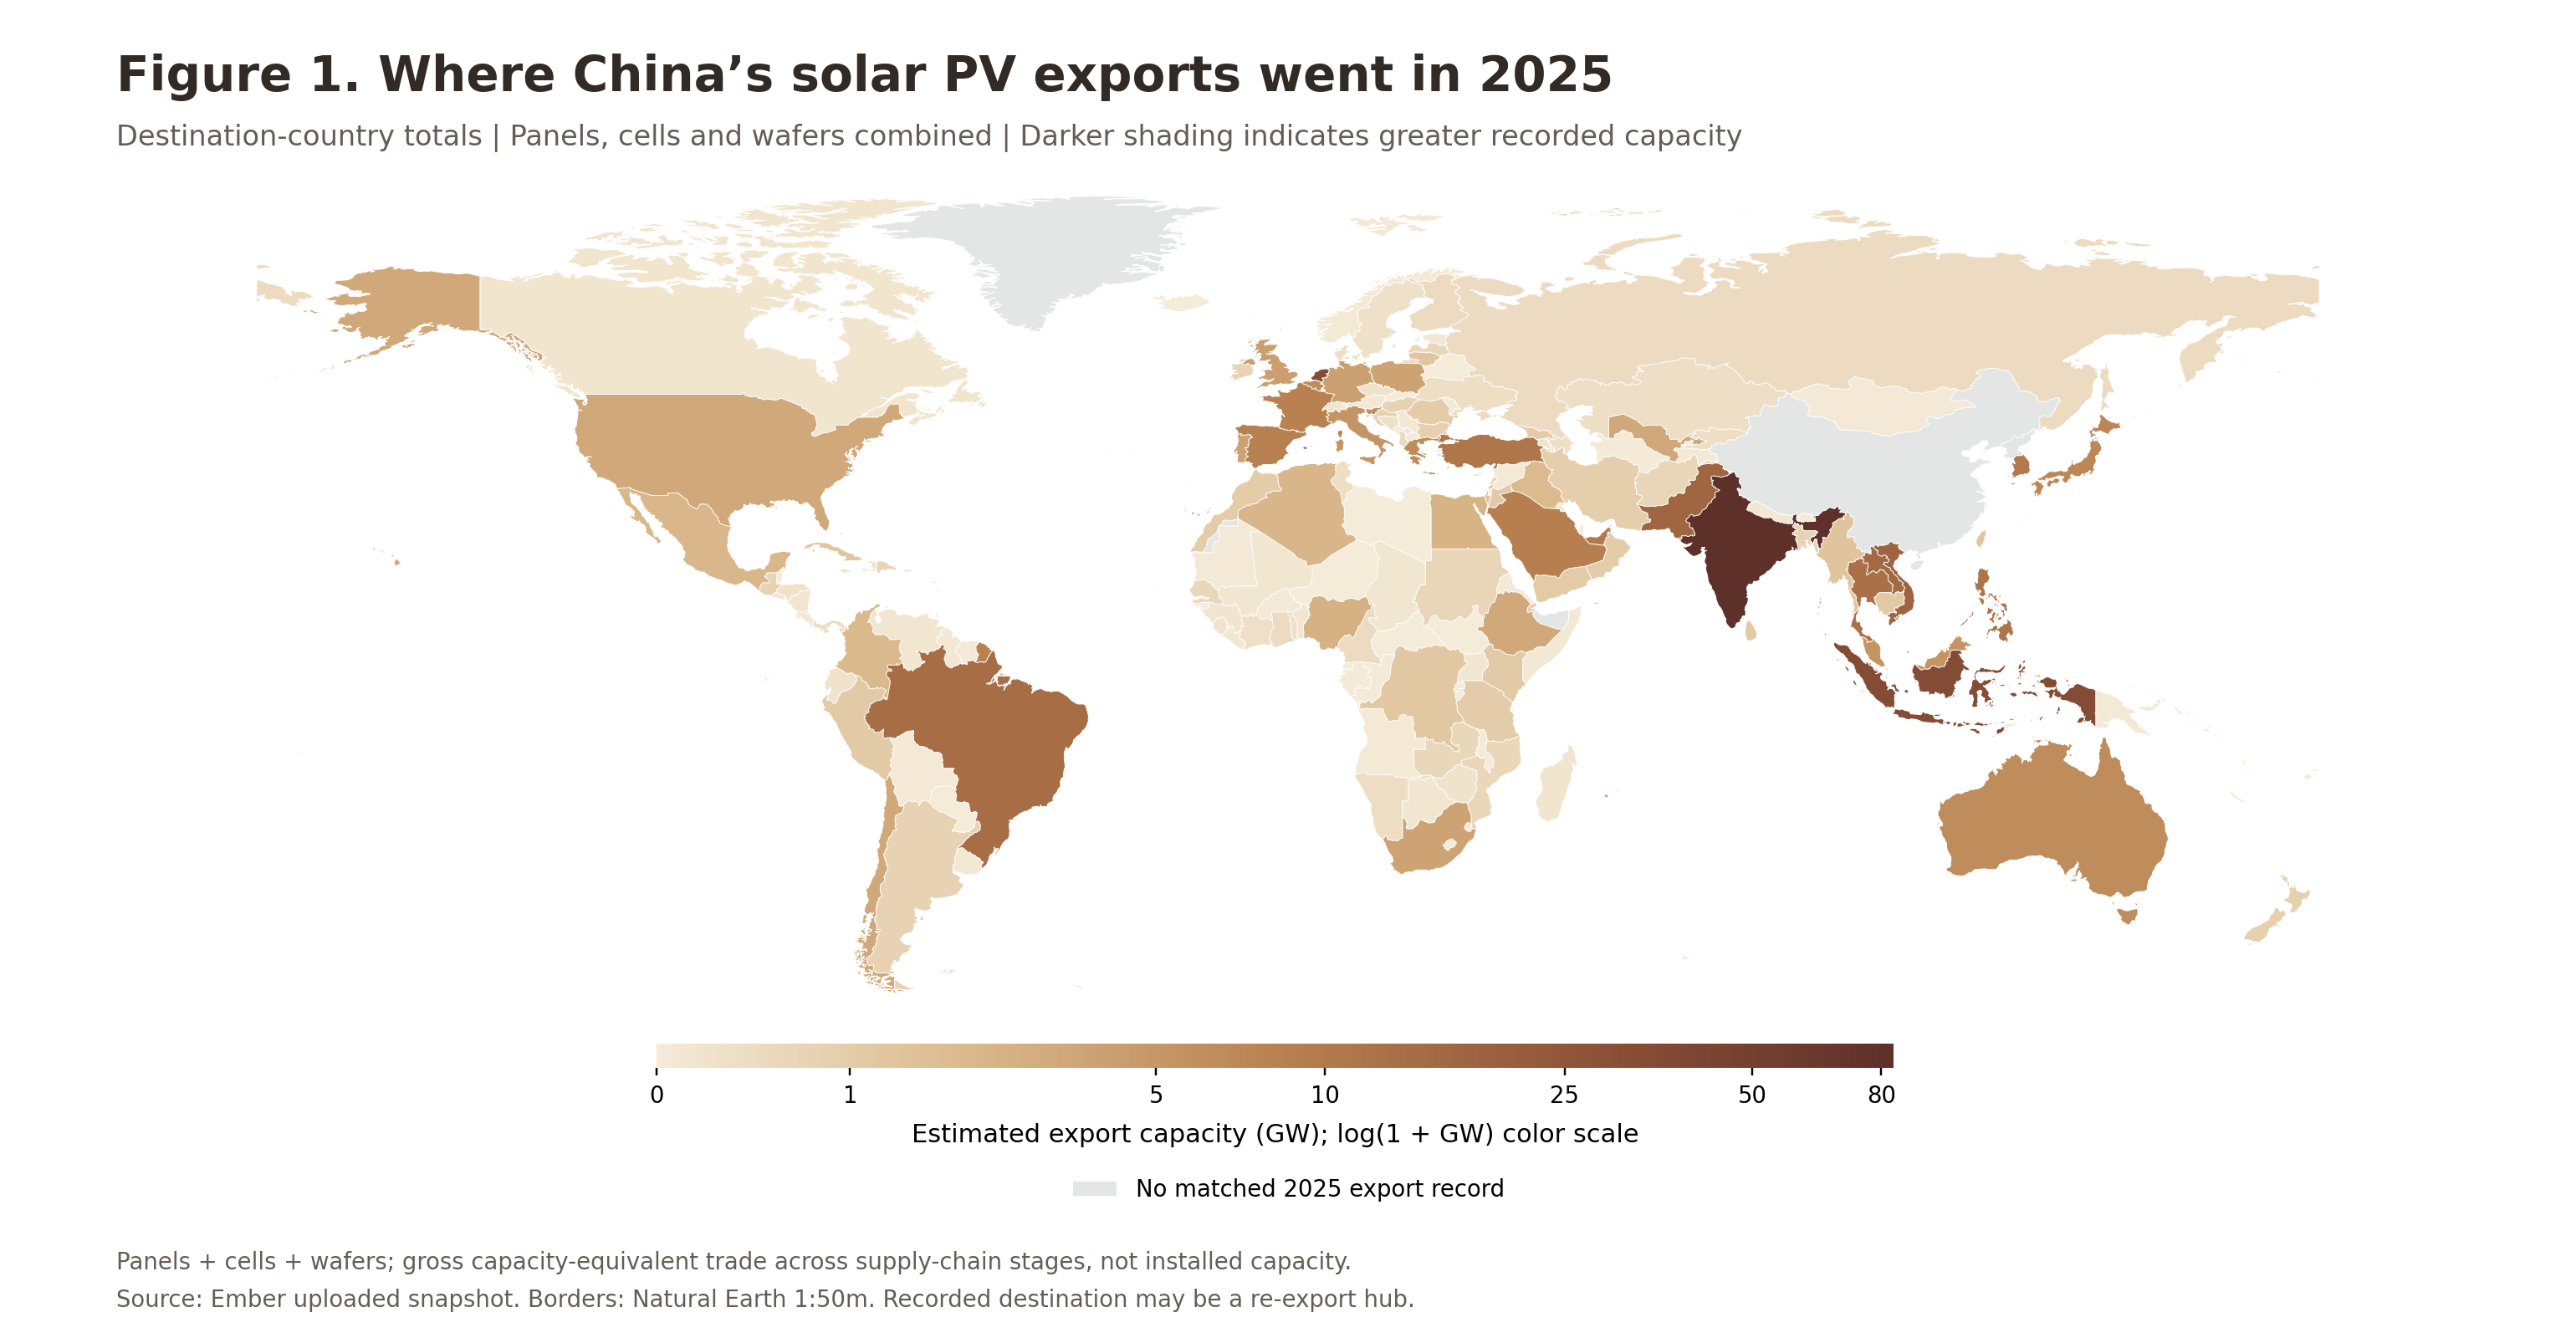

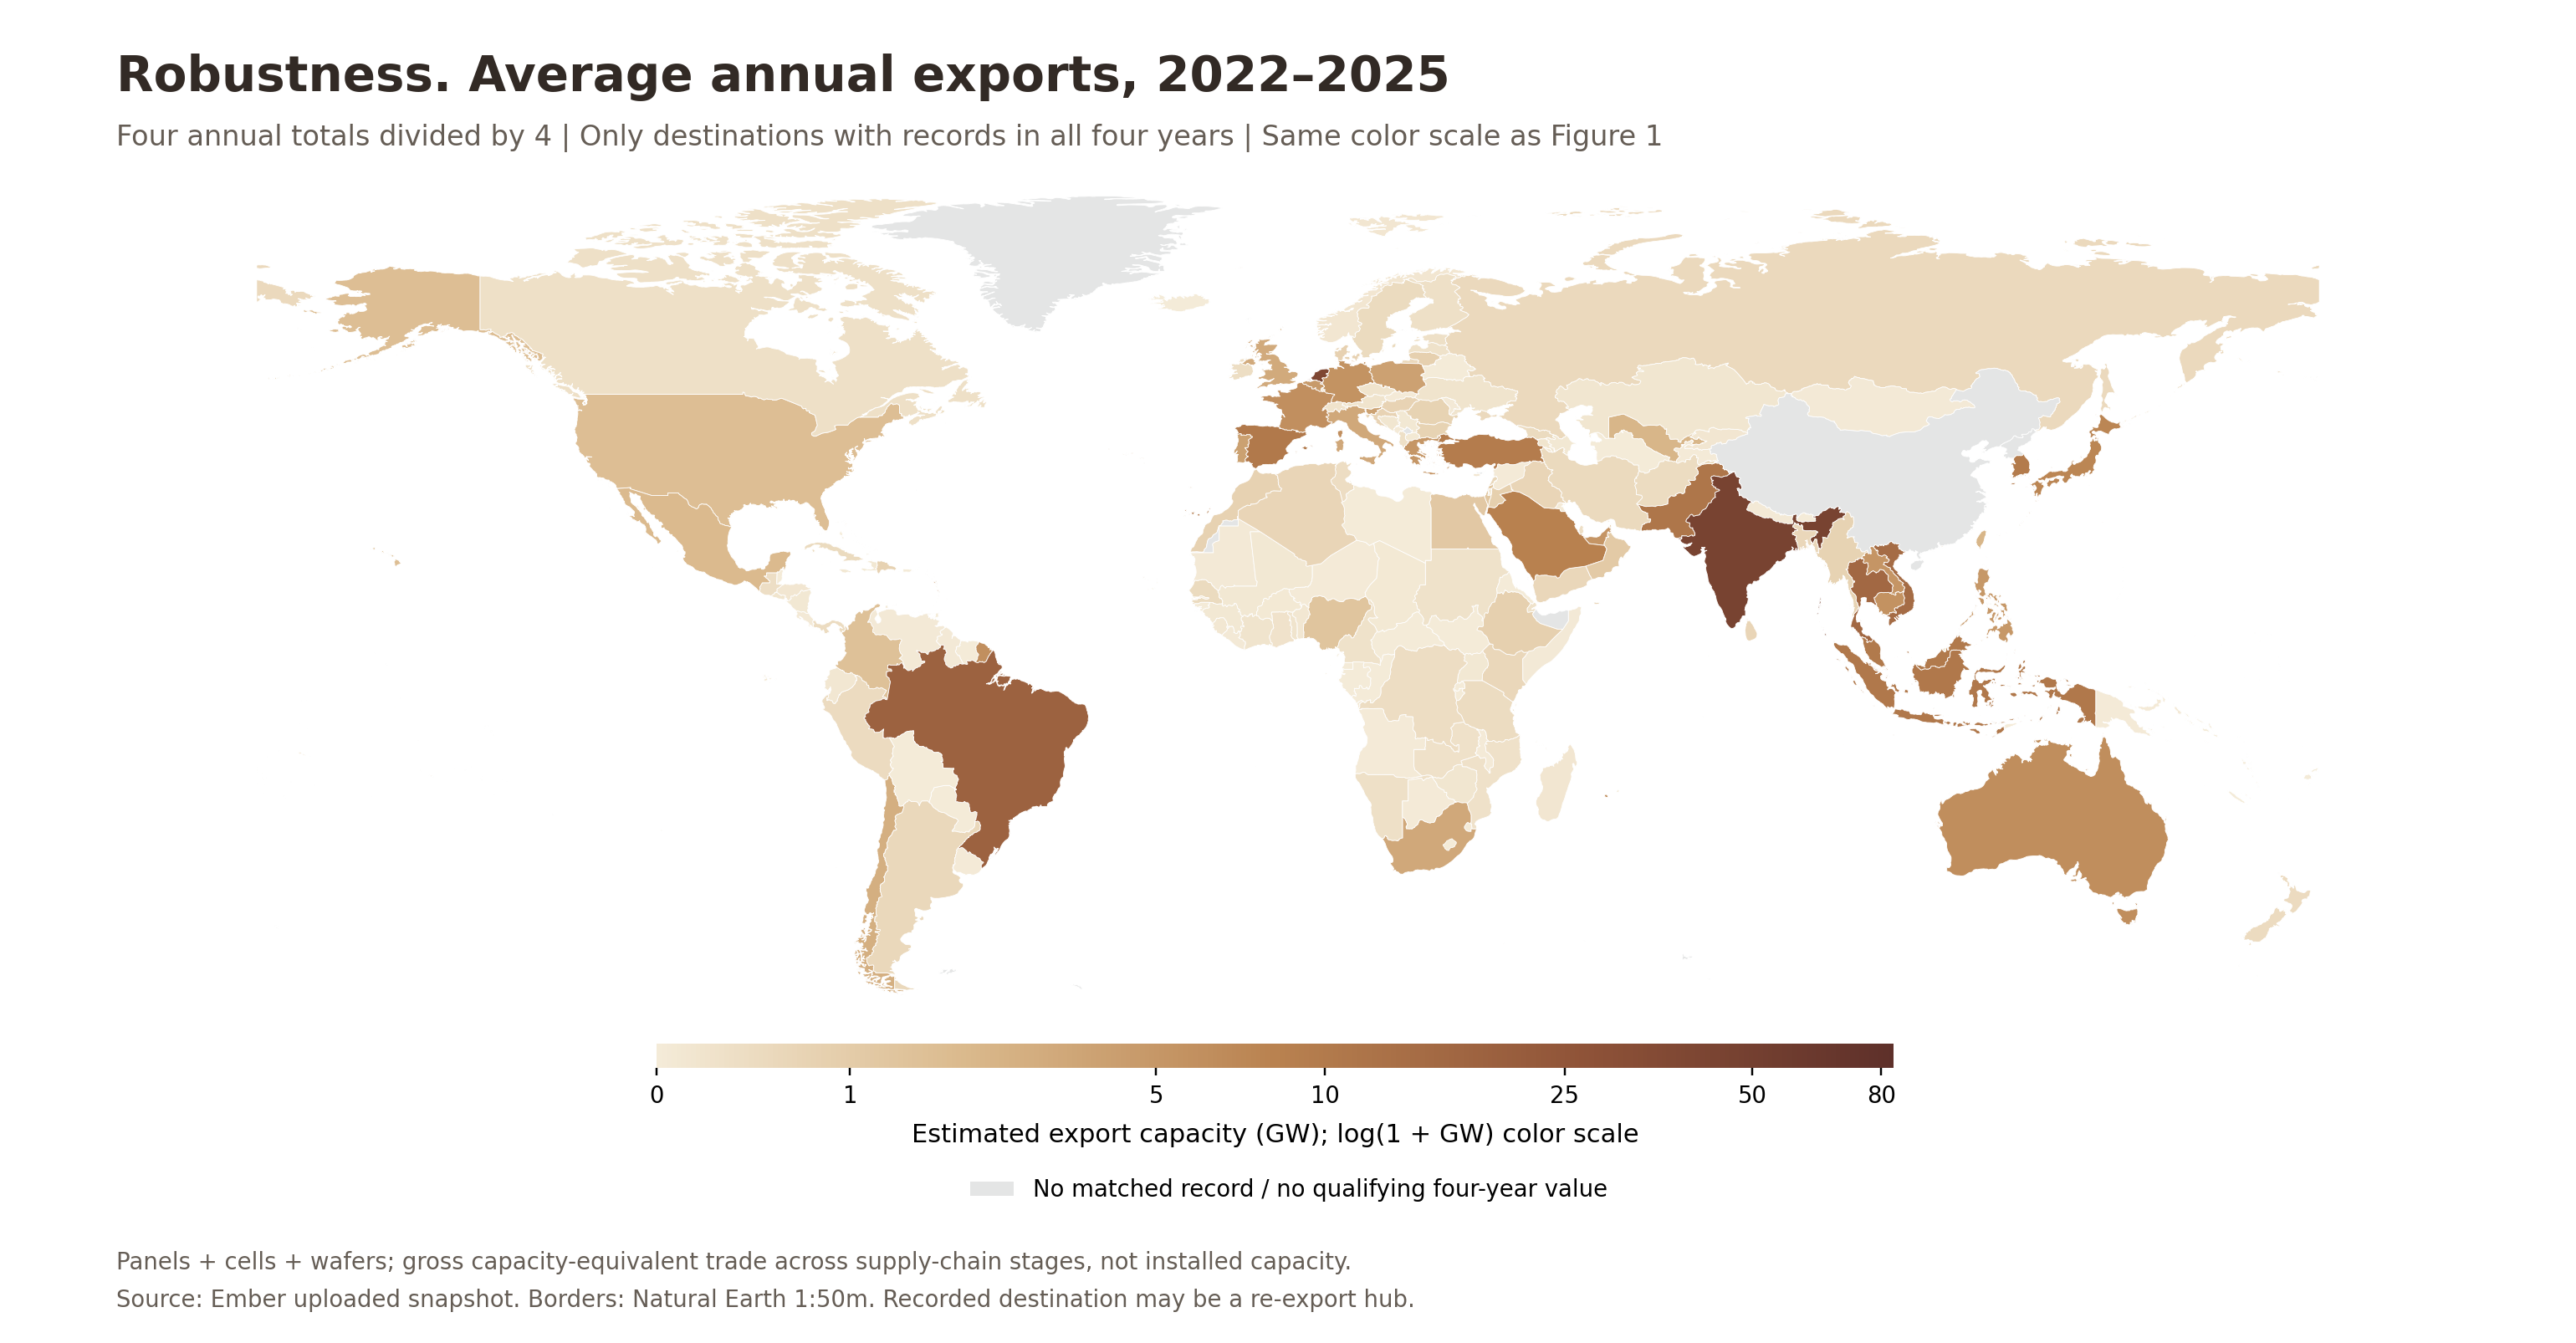

In [ ]:
from IPython.display import display, Image
display(Image(filename=str(PROJECT / 'figures/figure1_capacity_map_2025.png')))
display(Image(filename=str(PROJECT / 'figures/figure1_robustness_map_2022_2025.png')))

## 6. Interpretation and provisional findings



In [ ]:
first = summary.iloc[0]
first_products = {p: float(first[p + '_GW']) if pd.notna(first[p + '_GW']) else None for p in PRODUCTS}
dominant = max((p for p in PRODUCTS if first_products[p] is not None), key=lambda p: first_products[p])
dominant_share = 100 * first_products[dominant] / first['capacity_gw']
top3_share = summary.head(3)['share_of_recorded_total_pct'].sum()
mean_top = means[(means['Commodity type'] == 'Combined') & means['capacity_gw'].notna()].nlargest(1, 'capacity_gw').iloc[0]
findings = [
    f"{first['Area']} is the largest recorded destination in 2025, at {first['capacity_gw']:.2f} GW ({first['share_of_recorded_total_pct']:.1f}% of the {total_2025:.2f} GW recorded total). The top three destinations account for {top3_share:.1f}% of recorded capacity-equivalent exports.",
    f"{dominant} account for {dominant_share:.1f}% of {first['Area']}'s combined capacity-equivalent exports. A large combined total therefore does not establish equally large demand for finished panels.",
    f"Among {len(robust)} destinations with a record in every year, {top10_overlap} of the top 10 are shared by the 2025 and 2022–2025 annual-mean rankings (Spearman correlation={rank_correlation:.3f}). The leading destination by four-year mean is {mean_top['Area']}."
]
caption = f"""Figure 1. Estimated capacity of China's solar PV exports by recorded destination, 2025. Panels, cells and wafers are summed within each destination over the full calendar year and converted from MW to GW. Darker shading indicates greater recorded capacity on a log(1+GW) color scale; no population, land-area or deployment denominator is applied. Gray denotes no matched record or, in the comparison, no qualifying four-year value. The map covers {mapped_share:.3f}% of recorded capacity. Combined categories represent gross capacity-equivalent trade at different supply-chain stages, not installed capacity or unique final solar demand. Capacity is estimated by Ember, and first destinations can be re-export hubs. Source: Ember uploaded CSV and Natural Earth 1:50m boundaries."""
notes = f"""# Figure 1: market distribution

## Question
Where were China's solar PV exports concentrated in 2025, measured by combined estimated capacity across panels, cells and wafers?

## Caption
{caption}

## Provisional findings
""" + '\n'.join('- ' + item for item in findings) + f"""

## Robustness comparison
The comparison uses average annual capacity over 2022–2025, calculated from four annual totals divided by 4. It is not the mean of raw product-month rows. Destinations missing an entire year are excluded from that mean rather than implicitly set to zero. Both maps share the same color scale. Top-10 overlap is {top10_overlap}/10 and rank correlation is {rank_correlation:.3f} on the same {len(robust)} destinations. Compare the country-level rank table before claiming that the same priority markets persist.

## Data quality and limitations
- Geographic join rows before/after: {rows_before_join:,}/{len(clean):,}; the crosswalk uses a validated many-to-one join.
- Matched capacity share in 2025: {mapped_share:.3f}%. Unmapped destinations and their values are saved separately and remain in summary totals.
- No absent country-month or product observation is imputed as zero. Annual totals sum recorded rows; missing component cells in the table mean no product record, not verified zero trade.
- The four-year rule requires a record in each year, not a complete 48-month or 144-product-month panel. Differences in reporting coverage can still affect comparisons.
- A sequential log(1+GW) color scale reveals smaller flows while retaining actual GW labels. A choropleth gives large countries greater visual prominence and is less precise than a ranking table.
- Panels and cells use value/price-derived capacity; wafers use a weight-to-capacity conversion. The combined total is not unique installed capacity and cannot establish profitability.
- Recorded first destinations may be re-export hubs. Natural Earth boundaries are for geographic display, not a statement about sovereignty.

## Interactive report sketch and platform
Platform: Python/pandas + Matplotlib for reproducible analysis, with a standalone HTML/SVG report requiring no account or hosting service. Controls select 2025 versus the four-year annual mean, and Combined/Panels/Cells/Wafers. Hover displays capacity and share; the linked top-10 table supports exact comparisons. Cross-filtering an external trend chart is proposed future work, not implemented here.

## Revised task list
1. Team reviews product aggregation and the gross-trade interpretation.
2. Integrate Figure 1 and its discussion into the group report (this is only one component of the required 3–5 figures).
3. Add teammates' market-growth, product-mix and monthly-pattern views.
4. Review unmatched territories and coverage; retain audit outputs.
5. Keep processed data and scripts in GitHub and render the combined report from cleaned data.

## Sources
- {SOURCE_URL}
- {METHOD_URL}
- {GEO_URL}
"""
(PROJECT / 'reports/figure1_notes.md').write_text(notes)
print('\n'.join(findings))
print(f'Geographic coverage: {mapped_share:.3f}% of recorded capacity; {len(unmapped)} unmapped destinations in 2025.')

India is the largest recorded destination in 2025, at 83.65 GW (19.2% of the 436.65 GW recorded total). The top three destinations account for 34.6% of recorded capacity-equivalent exports.
Cells account for 59.2% of India's combined capacity-equivalent exports. A large combined total therefore does not establish equally large demand for finished panels.
Among 204 destinations with a record in every year, 7 of the top 10 are shared by the 2025 and 2022–2025 annual-mean rankings (Spearman correlation=0.969). The leading destination by four-year mean is India.
Geographic coverage: 99.989% of recorded capacity; 7 unmapped destinations in 2025.


## 7. Export the interactive report



In [ ]:

def ring_to_svg(ring):
    return 'M' + 'L'.join(f'{(lon+180)*3.2:.2f},{(85-lat)*3.2:.2f}' for lon, lat, *rest in ring) + 'Z'

svg_parts = []
for feature in features:
    geom = feature['geometry']
    polys = [geom['coordinates']] if geom['type'] == 'Polygon' else geom['coordinates']
    path_data = ''.join(ring_to_svg(ring) for polygon in polys for ring in polygon)
    import html as html_module
    label = feature['properties'].get('NAME_EN') or feature['properties']['ADMIN']
    svg_parts.append(f'<path class="country" data-code="{feature["id"]}" data-name="{html_module.escape(label, quote=True)}" d="{path_data}" fill-rule="evenodd"/>')
interactive_data = {}
for period, frame in [('2025', main), ('mean', means)]:
    interactive_data[period] = {}
    for product in ['Combined'] + PRODUCTS:
        sub = frame[(frame['Commodity type'] == product) & frame['capacity_gw'].notna()]
        rows = [{'area': r.Area, 'iso3': r.iso3 if pd.notna(r.iso3) else None, 'gw': float(r.capacity_gw)} for r in sub.itertuples()]
        interactive_data[period][product] = rows
payload = json.dumps(interactive_data, ensure_ascii=False).replace('</', '<\\/')
html_template = r'''<!doctype html><html lang="en"><head><meta charset="utf-8"><meta name="viewport" content="width=device-width, initial-scale=1"><title>Figure 1 | China solar PV exports</title><style>
body{font:15px/1.55 Arial,sans-serif;color:#342c26;max-width:1240px;margin:32px auto;padding:0 24px}h1{font-size:29px;margin-bottom:5px}h2{font-size:21px;margin-top:32px}.sub,.note{color:#6c6258}.controls{display:flex;gap:20px;flex-wrap:wrap;margin:22px 0}select{font:inherit;padding:7px 10px;border:1px solid #bcb1a5;border-radius:4px;background:white}.country{fill:#e4e5e5;stroke:white;stroke-width:.45}.country:hover{stroke:#31271f;stroke-width:1.2}svg{width:100%;height:auto}.legend{height:13px;width:480px;max-width:90%;background:linear-gradient(to right,#F4EBD8,#DAB98C,#B98250,#8F5338,#5E302A);margin:10px auto 3px}.legendtext{text-align:center;font-size:12px}.tooltip{position:fixed;background:#fffaf2;border:1px solid #b9a68d;padding:10px;pointer-events:none;display:none;max-width:300px;box-shadow:0 2px 8px #0002}table{border-collapse:collapse;width:100%;font-size:14px;margin:15px 0}th,td{padding:9px;border-bottom:1px solid #e1d8cc;text-align:right}th:first-child,td:first-child{text-align:left}th{background:#f1e8d8}details{margin:18px 0}pre{white-space:pre-wrap;background:#f6f3ed;padding:16px;font-size:12px}li{margin:8px 0}a{color:#794b36}.image{max-width:100%}</style></head><body>
<h1>Figure 1. Where China's solar PV exports went</h1><p class="sub">A geographic view of recorded exports, with a linked ranking table.</p>
<div class="controls"><label>Period <select id="period"><option value="2025">2025 annual total</option><option value="mean">2022–2025 average annual total</option></select></label><label>Product <select id="product"><option>Combined</option><option>Panels</option><option>Cells</option><option>Wafers</option></select></label></div>
<p id="status"></p><svg viewBox="0 0 1152 457.6" role="img" aria-label="World choropleth of recorded export capacity">__SVG__</svg>
<div class="legend"></div><p class="legendtext" id="legendtext"></p><p class="note">Gray: no matched/qualifying record. Hover over a country for details. Shares use all recorded destinations in the selected view, including unmapped ones. The color maximum is fixed across views.</p>
<div id="tip" class="tooltip"></div><h2>Top 10 recorded destinations</h2><div id="ranking"></div>
<h2>Question, units and limitations</h2><p>Which destinations account for the largest recorded export capacity? Values are annual GW, or mean annual GW, with no population or land-area denominator. Color is log(1+GW). Combined Panels/Cells/Wafers measures gross capacity-equivalent trade across supply-chain stages, not installed capacity or unique final demand. Country area affects visual prominence; use the table for precise ranking.</p>
<p>Capacity is estimated by Ember; recorded destinations may be re-export hubs. Missing product/month records are not verified zero exports. The four-year mean requires a record in each year but not every month. Unmapped territories remain in totals. Natural Earth boundaries are used for display.</p>
<h2>Provisional findings</h2><ul>__FINDINGS__</ul>
<h2>Robustness</h2><p>__ROBUST__</p><img class="image" alt="Four-year mean map using same color scale" src="data:image/png;base64,__ROBUSTPNG__">
<h2>2025 product breakdown</h2>__TABLE__
<h2>Geographic matching audit</h2><p>__AUDIT__</p>__UNMAPPED__
<h2>Platform and next tasks</h2><p>Python/pandas and Matplotlib generate this self-contained HTML/SVG report. Implemented controls: period, product, hover, linked top-10 table. Planned next: integrate the group's market-growth and monthly-pattern views. This Figure 1 report alone does not supply the assignment's full 3–5 figures.</p>
<details><summary>Reproducible Python analysis code</summary><pre>__CODE__</pre></details>
<p class="note">Sources: <a href="https://ember-energy.org/data/china-solar-exports-data/">Ember data</a>, <a href="https://files.ember-energy.org/public-downloads/ember_china_solar_exports_methodology_v4.pdf">Ember methodology v4</a>, <a href="https://www.naturalearthdata.com/">Natural Earth</a>.</p>
<script>
const data=__DATA__;const maxGW=__MAX__;const colors=['#F4EBD8','#DAB98C','#B98250','#8F5338','#5E302A'];let active={},denominator=0;
function rgb(hex){return [1,3,5].map(i=>parseInt(hex.slice(i,i+2),16));}
function shade(gw){let t=Math.max(0,Math.min(1,Math.log1p(gw)/Math.log1p(maxGW)))*4,i=Math.min(3,Math.floor(t)),f=t-i,a=rgb(colors[i]),b=rgb(colors[i+1]);return 'rgb('+a.map((x,j)=>Math.round(x+(b[j]-x)*f)).join(',')+')';}
function esc(s){return String(s).replace(/[&<>"']/g,c=>({'&':'&amp;','<':'&lt;','>':'&gt;','"':'&quot;',"'":'&#39;'}[c]));}
function update(){let period=document.getElementById('period').value,product=document.getElementById('product').value,rows=data[period][product].slice().sort((a,b)=>b.gw-a.gw);denominator=rows.reduce((s,r)=>s+r.gw,0);active={};rows.forEach(r=>{if(r.iso3)active[r.iso3]=r;});document.querySelectorAll('.country').forEach(p=>{let r=active[p.dataset.code];p.style.fill=r?shade(r.gw):'#e4e5e5';});document.getElementById('status').textContent=(period==='2025'?'2025':'2022–2025 average annual')+' · '+product+' · '+denominator.toFixed(2)+' GW recorded total across '+rows.length+' destinations';document.getElementById('ranking').innerHTML='<table><tr><th>Destination</th><th>Capacity (GW)</th><th>Share (%)</th></tr>'+rows.slice(0,10).map(r=>'<tr><td>'+esc(r.area)+'</td><td>'+r.gw.toFixed(3)+'</td><td>'+(100*r.gw/denominator).toFixed(2)+'</td></tr>').join('')+'</table>';document.getElementById('legendtext').textContent='0 → '+maxGW.toFixed(2)+' GW | log(1+GW) color scale';}
const tip=document.getElementById('tip');document.querySelectorAll('.country').forEach(p=>{p.addEventListener('mousemove',e=>{let r=active[p.dataset.code];tip.innerHTML='<strong>'+esc(r?r.area:p.dataset.name)+'</strong><br>'+(r?r.gw.toFixed(3)+' GW<br>'+(100*r.gw/denominator).toFixed(2)+'% of recorded total':'No matched/qualifying record');tip.style.display='block';tip.style.left=Math.min(e.clientX+15,window.innerWidth-310)+'px';tip.style.top=Math.min(e.clientY+15,window.innerHeight-120)+'px';});p.addEventListener('mouseleave',()=>tip.style.display='none');});document.getElementById('period').addEventListener('change',update);document.getElementById('product').addEventListener('change',update);update();
</script></body></html>'''
robust_sentence = f'The comparison includes {len(robust)} destinations with records in all four years. The 2025 and four-year mean top-10 rankings share {top10_overlap} countries; Spearman rank correlation is {rank_correlation:.3f}. The mean map uses the same color scale as the 2025 map. This tests window sensitivity, not profitability.'
audit_sentence = f'The country crosswalk preserves {rows_before_join:,} rows before and {len(clean):,} after matching. {int(main_combined["mapped"].sum())} of {len(main_combined)} recorded destinations in 2025 match the map, covering {mapped_share:.3f}% of recorded capacity. Unmapped areas are listed below.'
report_table = top10[['Area', 'Panels_GW', 'Cells_GW', 'Wafers_GW', 'capacity_gw', 'share_of_recorded_total_pct']].rename(columns={'capacity_gw': 'Combined_GW', 'share_of_recorded_total_pct': 'Share_pct'})

analysis_code = globals().get('ANALYSIS_SOURCE', 'See Figure1_Capacity_Map.ipynb or scripts/figure1.py in the accompanying package.')
report = html_template.replace('__SVG__', ''.join(svg_parts)).replace('__DATA__', payload).replace('__MAX__', str(float(color_max_gw)))
report = report.replace('__FINDINGS__', ''.join('<li>' + html_module.escape(s) + '</li>' for s in findings))
report = report.replace('__ROBUST__', html_module.escape(robust_sentence)).replace('__AUDIT__', html_module.escape(audit_sentence))
report = report.replace('__ROBUSTPNG__', base64.b64encode((PROJECT / 'figures/figure1_robustness_map_2022_2025.png').read_bytes()).decode())
report = report.replace('__TABLE__', report_table.to_html(index=False, float_format=lambda v: f'{v:.3f}', na_rep='No record', border=0))
report = report.replace('__UNMAPPED__', unmapped.to_html(index=False, float_format=lambda v: f'{v:.6f}', border=0))
report = report.replace('__CODE__', html_module.escape(analysis_code))
(PROJECT / 'reports/figure1_report.html').write_text(report, encoding='utf-8')

2121596


## 8. Reconcile totals

Confirm country/product totals reconcile with the cleaned records and that the geographic join did not duplicate rows.

In [ ]:
assert np.isclose(clean.loc[clean['year'] == 2025, 'capacity_gw'].sum(), total_2025)
assert np.isclose(summary[[p + '_GW' for p in PRODUCTS]].sum(axis=1, min_count=1).sum(), total_2025)
assert summary['Area'].is_unique and main_combined['Area'].is_unique
assert len(clean) == rows_before_join
print('Saved:', PROJECT / 'figures/figure1_capacity_map_2025.png')
print('Saved:', PROJECT / 'reports/figure1_report.html')
print('Saved:', PROJECT / 'reports/figure1_notes.md')

Saved: solar_pv_figure1/figures/figure1_capacity_map_2025.png
Saved: solar_pv_figure1/reports/figure1_report.html
Saved: solar_pv_figure1/reports/figure1_notes.md
